In [16]:
import numpy as np

start_time = 60497.020
end_time = 60537.882

delta_DM = 0.381

delta_RM = 82.93
delta_RM_err = 41.3



length_scale_lim_cm = (end_time-start_time)*24*60*60*3e10
length_scale_lim_km = length_scale_lim_cm/1e5
length_scale_lim_pc = length_scale_lim_cm/3.086e18


print('Length scale limit is:', length_scale_lim_pc, ' parsec')
 

# print(f"RM window: {(RM_middle_time-RM_start_time):.2f} days -- delta RM: {delta_RM:.2f} rmunit")
# print(f"DM window: {(DM_middle_time-DM_start_time):.2f} days -- delta DM: {delta_DM:.2f} dmunit")




print('Delta RM across ', end_time-start_time,' is ',delta_RM,'+=',delta_RM_err)

delta_RM_lower = delta_RM - delta_RM_err
delta_RM_upper = delta_RM + delta_RM_err






Length scale limit is: 0.03432090213869169  parsec
Delta RM across  40.86200000000099  is  82.93 += 41.3


The equations for dispersion measure and rotation measure are:

${\rm DM} = \int_0^d n_e(l) dl$ 

${\rm RM} = 0.812 \int_d^0 B_{\parallel} n_e(l) dl$``

Note that the units here are the standard: rad m^-2, uG, and pc cm^-3. Lets first assume that the changes in RM and DM come from exactly the same uniform plasma, e.g., changes along the line of sight for these two values are completely correlated and the material is uniform along its observer axis length. Therefore we can simplify the expressions:

${\rm DM} = n_e L$ 

${\rm RM} = 0.812 B_{\parallel} n_e L$

Where L is the length scale associated with the isotropic plasma. Then we can substitute DM in the second equation:

${\rm RM} = 0.812 B_{\parallel} DM$ 

and finally look at the changes:

$\delta{\rm RM} = 0.812 B_{\parallel} \delta DM$ 

Solving for $B_{\parallel}$:

$B_{\parallel} = \frac{1}{0.812} \frac{\delta RM}{\delta DM}$




In [17]:
B_parallel_uG = (delta_RM/(0.812 * delta_DM))
B_parallel_uG_err = delta_RM_err/(0.812 * delta_DM)
# print(f'Derived B in mG: {(B_parallel_uG):.5f}')
print(f'Derived B in mG: {(B_parallel_uG/1e3):.5f}')
print(f'Derived B_err in mG: {(B_parallel_uG_err/1e3):.5f}')


Derived B in mG: 0.26806
Derived B_err in mG: 0.13350


${\rm RM} = 0.812 B_{\parallel} n_e L$

We can express $B_{\parallel}$ in terms of the partcle energy:




$B_{\parallel} = (\beta^{-1} 16 \pi n_e k_B T)^{1/2}$

Now we can sub in the fact that we are approximating $\delta RM = 0.812 n_e L B_{\parallel}$ recalling that $B_{\parallel} here is in uG, such that: $B_{\parallel} = 10^{6} \delta RM/(0.812 n_e L)$ in G. 

so subbing in:

$10^{-6} \delta RM/(0.812 n_e L) = (\beta^{-1} 16 \pi n_e k_B T)^{1/2}$

${\rm RM} = 0.812 \times 10^{6}  (\beta^{-1} 16 \pi n_e k_B T)^{1/2} n_e L$

and rearranging:

$n_e^{3/2} =  {\rm RM} 10^{-6} /(0.812 (\beta^{-1} 16 \pi k_B T)^{1/2} L)$

$n_e^{3/2} =  {\rm RM} \beta^{1/2} /(0.812 (16 \pi k_B T)^{1/2} L)$

$n_e =  {\rm RM}^{2/3} (10^{-6})^{2/3} \beta^{1/3} /(0.812^{2/3} (16 \pi k_B T)^{1/3} L^{2/3})$


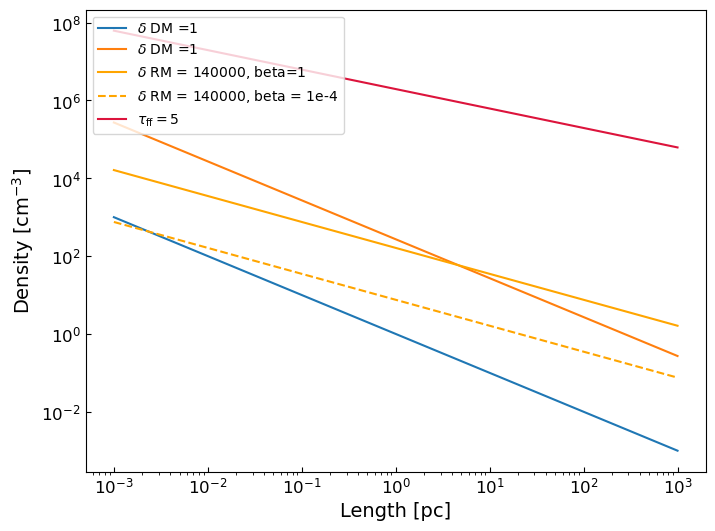

In [18]:
# First I use this to recreate the Fig. from Michilli et al., for T = 1e6x

km_cm = 1e5
day_seconds = 24.*60.*60.
boltzman = 1.38e-16
import matplotlib.pyplot as plt
c = 3e10


L_arr = np.logspace(-3,3) # Length in parsec
n_e_arr = np.logspace(-1,5) # Density scale



fig, ax= plt.subplots(figsize=(8, 6))  

plt.plot(L_arr, 1/L_arr,label='$\delta$ DM =1'.format(delta_DM))
plt.plot(L_arr, 271/L_arr,label='$\delta$ DM =1'.format(delta_DM))
# plt.plot(L_arr, 0.01/L_arr,label='$\delta$ DM ={}'.format(0.01))


# Let T = 1e8 K, lets compute for different betas 

# ratios = [0.0001, 100]

# n_e = 

# plt.plot(L_arr,(np.abs(delta_RM)/(L_arr)

plt.plot(L_arr, 1e-6**(2/3)*(140000**(2/3) * 1**(1/3)) /(0.812**(2/3) * (16 *np.pi*boltzman*1e6)**(1/3) * L_arr**(2/3)),label='$\delta$ RM = 140000, beta=1',color='orange',linestyle='-')
# plt.plot(L_arr, (np.abs(140000)/(L_arr*0.812*16 * np.pi *1e8 * boltzman))**(1/2),label='RM = -182.2, beta=1.')

plt.plot(L_arr, 1e-6**(2/3)*(140000**(2/3) *1e-4**(1/3)) /(0.812**(2/3) * (16 *np.pi*boltzman*1e6)**(1/3) * L_arr**(2/3)),label='$\delta$ RM = 140000, beta = 1e-4',color='orange',linestyle='--')
# plt.plot(L_arr, (1e-4*np.abs(RM_start_value)/(L_arr*0.812*16 * np.pi *1e8 * boltzman))**(1/2),label='RM = -182.2, beta=1e-4')


plt.plot(L_arr, (5/(1.3e-12*L_arr))**(1/2),label=r'$\tau_{\rm ff} = 5$',color='crimson')



plt.xscale('log')
plt.yscale('log')
plt.xlabel('Length [pc]', fontsize=14)
plt.ylabel(r'Density [${\rm cm}^{-3}$]', fontsize=14)
plt.tick_params(axis='both', direction='in', top=False, right=False, labelsize=12)
plt.legend(loc=2)
plt.show()

0.0011441569213440277
0.03432470764032083


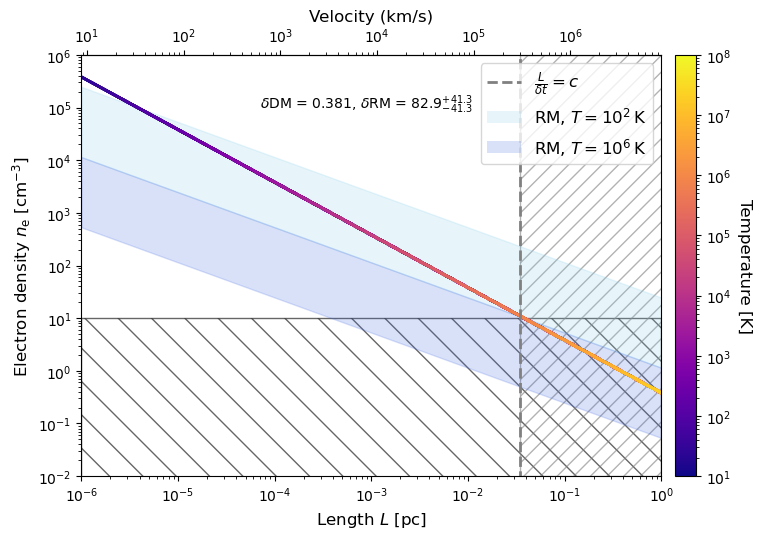

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import matplotlib as mpl
import matplotlib.lines as mlines




# ----------- INPUT PARAMETERS ----------------
boltzman  = 1.380649e-16  # erg/K
# delta_DM  = 1.0           # pc cm⁻³
delta_RM_nominal =delta_RM  # rad m⁻² (central value)

T_min, T_max = 1e1, 1e8
n_T     = 80                     # Temperature samples
L_arr   = np.logspace(-6, 1, 1000)  # pc
betas   = [1, 1e-4]            # bounding beta values
# ---------------------------------------------

temperatures = np.logspace(np.log10(T_min), np.log10(T_max), n_T)
segments_dm, t_dm = [], []

for T in temperatures:
    n_e_DM = delta_DM / L_arr

    pref_nom = (1e-6)**(2/3) * (abs(delta_RM_nominal)**(2/3)) / (
        0.812**(2/3) * (16 * np.pi * boltzman * T)**(1/3))
    n_e_RM_beta1   = pref_nom / L_arr**(2/3)
    n_e_RM_beta1e4 = pref_nom * (1e-4)**(1/3) / L_arr**(2/3)

    ok = np.where((n_e_DM > n_e_RM_beta1e4) & (n_e_DM < n_e_RM_beta1))[0]
    if ok.size < 2:
        continue

    pts = np.column_stack([L_arr[ok], n_e_DM[ok]])
    segs = np.concatenate([pts[:-1, None, :], pts[1:, None, :]], axis=1)

    segments_dm.append(segs)
    t_dm.append(np.full(len(segs), T))

segments_dm = np.concatenate(segments_dm)
t_dm = np.concatenate(t_dm)

# Envelope segments for RM bounds
segments_env = []
for T in temperatures:
    for dRM in (delta_RM_lower, delta_RM_upper):
        pref = (1e-6)**(2/3) * (abs(dRM)**(2/3)) / (
            0.812**(2/3) * (16 * np.pi * boltzman * T)**(1/3))
        for beta in betas:
            n_e_RM = pref * beta**(1/3) / L_arr**(2/3)
            pts = np.column_stack([L_arr, n_e_RM])
            segs = np.concatenate([pts[:-1, None, :], pts[1:, None, :]], axis=1)
            segments_env.append(segs)

segments_env = np.concatenate(segments_env)

# --------- PLOTTING ----------
fig, ax = plt.subplots(figsize=(8, 5.5))


# Colored DM track
norm = mpl.colors.LogNorm(vmin=T_min, vmax=T_max)
lc_dm = LineCollection(segments_dm, cmap='plasma', norm=norm, linewidth=2)
lc_dm.set_array(t_dm)
ax.add_collection(lc_dm)

ax.set_xscale('log')
ax.set_yscale('log')
ax.autoscale()
ax.set_xlabel('Length $L$ [pc]',fontsize=12)
ax.set_ylabel(r'Electron density $n_{\rm e}$ [cm$^{-3}$]',fontsize=12)
plt.text(7e-5,1e5,
    r'$\delta$DM = {:.3g}, $\delta$RM = {:.1f}$^{{+{:.1f}}}_{{-{:.1f}}}$'.format(
        delta_DM, delta_RM_nominal,
        delta_RM_upper - delta_RM_nominal,
        delta_RM_nominal - delta_RM_lower
    )
)

# Colorbar
cbar = fig.colorbar(lc_dm, ax=ax, pad=0.02)
cbar.set_label('Temperature [K]', rotation=270, labelpad=15,fontsize=12)

# Legend (with proxy artists)
# proxy_env = mlines.Line2D([], [], color='lightgrey', lw=1.5, label=r'RM envelope ($\beta=1,10^{-4}$)')
# proxy_dm  = mlines.Line2D([], [], color='black', lw=2, label=r'Allowed $n_e$ (colour = $T$)')
# ax.legend(handles=[proxy_dm, proxy_env], loc='lower left', frameon=False)


def km_s_to_l_pc(v):
    
    pc_km = 3.2408e-14
    
    return v*pc_km * (end_time - start_time)*day_seconds 

print(km_s_to_l_pc(1e4))

def l_pc_to_km_s(L_pc):
    
    return (L_pc/(3.2408e-14))/((end_time - start_time)*day_seconds)
    

print(km_s_to_l_pc(3e10/(1e5)))
    
secax = ax.secondary_xaxis('top', functions=(l_pc_to_km_s, km_s_to_l_pc))
secax.set_xlabel('Velocity (km/s)', fontsize=12)


plt.vlines(1e1,1e-10,1e10,color='black',linestyle='--',linewidth=2)

ax.axhspan(1e1,1e-3,
           facecolor='none', hatch='\\', edgecolor='black', alpha=0.6,
           zorder=0)

plt.vlines(km_s_to_l_pc(3e10/(1e5)),1e-10,1e10,label=r'$\frac{L}{\delta t} = c$',color='grey',linestyle='--',linewidth=2)

ax.axvspan(km_s_to_l_pc(3e10/(1e5)),1e2,
           facecolor='none', hatch='//', edgecolor='grey', alpha=0.6,
           zorder=0)


# Now do fill between for background lines
T = 1e2
line_RM_beta1 = 1e-6**(2/3)*(np.abs(delta_RM)**(2/3) * 1**(1/3)) /(0.812**(2/3) * (16 *np.pi*boltzman*T)**(1/3) * L_arr**(2/3))
line_RM_beta1e4 = 1e-6**(2/3)*(np.abs(delta_RM)**(2/3) * (10**(-4))**(1/3)) /(0.812**(2/3) * (16 *np.pi*boltzman*T)**(1/3) * L_arr**(2/3))
plt.fill_between(L_arr, line_RM_beta1, line_RM_beta1e4,color='skyblue', alpha=0.2)

T = 1e6
line_RM_beta1 = 1e-6**(2/3)*(np.abs(delta_RM)**(2/3) * 1**(1/3)) /(0.812**(2/3) * (16 *np.pi*boltzman*T)**(1/3) * L_arr**(2/3))
line_RM_beta1e4 = 1e-6**(2/3)*(np.abs(delta_RM)**(2/3) * (10**(-4))**(1/3)) /(0.812**(2/3) * (16 *np.pi*boltzman*T)**(1/3) * L_arr**(2/3))
plt.fill_between(L_arr, line_RM_beta1, line_RM_beta1e4,color='royalblue', alpha=0.2)


from matplotlib.patches import Patch

# create a sky-blue patch with the same alpha:
rm_patch = Patch(facecolor='skyblue', alpha=0.2,
                 label=r'RM, $T = 10^{2}\,\mathrm{K}$')

rm_patch_2 = Patch(facecolor='royalblue', alpha=0.2,
                 label=r'RM, $T = 10^{6}\,\mathrm{K}$')

# plt.scatter(1., 1e2, color='black', label='Crab Nebula', marker='o', s=100)  # Star
# plt.scatter(0.1, 1e3, color='black', label='SN 1987a', marker='D', s=100)  # Circle
# plt.scatter(0.01, 1e4, color='black', label='Crab Filament', marker='s', s=100)  # Diamond


# put it into the existing legend
handles, labels = ax.get_legend_handles_labels()
handles.append(rm_patch)
handles.append(rm_patch_2)
# plt.legend(handles=handles, labels=labels, frameon=False)



plt.xlim(1e-6,1e0)
plt.ylim(1e-2,1e6)
plt.legend(handles=handles, frameon=True, fontsize=12,loc='upper right')
plt.tight_layout()
plt.savefig('DM_RM_constraints.pdf',dpi=300)
plt.show()